# Notebook 2 — pretrained Flow AM / terminal-gradient reliability

**noise→action generation，不是物理导航。** 固定单一条件的二维终止 bandit，
$Q_{true}(s,a)=R(a)$。先真实训练行为 Flow，再冻结 base 和五成员 scalar reward
ensemble。研究终端梯度误差→伴随→matching 标签→参数梯度→Adam 步→有限预算性能。
本平台不是完整 Q-learning、TRQAM、OGBench，也不预设 oracle 必须胜出。
旧 [导航 SOC notebook](archive/02_navigation_am_and_candidates.ipynb) 原样归档；
Notebook 1 与历史资产/结论保持不变。此源码包含完整实验，不调用历史 replay。

依据：[A, §4/5.2, Algorithm 1, G.1](https://arxiv.org/html/2409.08861v5)，
[B, §3–4](https://arxiv.org/html/2601.14234v3)。公式以下按本实验独立推导。
官方实现核对对象：[ColinQiyangLi/qam, agents/qam.py](https://github.com/ColinQiyangLi/qam/blob/2726d767c9a0a7a46d49693f0391f73dc2cf58ac/agents/qam.py)，
commit `2726d767c9a0a7a46d49693f0391f73dc2cf58ac`，`adj_matching` / `actor_loss`。
这是审计参考，不是逐行复现；具体差异见下面的端点表。

In [1]:
import copy
import hashlib
import json
import math
import os
import platform
import sys
import tempfile
import time
import traceback
from contextlib import contextmanager
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy.stats import t as student_t
from torch import nn


@dataclass(frozen=True)
class FlowConfig:
    profile: str = 'formal'
    seeds: tuple = (28001, 28002, 28003)
    seed_scheme: str = 'root_seed * 10000000 + role_offset'
    means: tuple = ((-1.5, -1.5), (-1.5, 1.5), (1.5, -1.5), (1.5, 1.5))
    weights: tuple = (.25, .25, .25, .25)
    behavior_std: float = .4
    reward_heights: tuple = (.2, .8, 1.4, 2.)
    reward_width: float = .85
    reward_quadratic: float = .025
    observation_std: float = .2
    behavior_train: int = 4096
    behavior_valid: int = 2048
    reward_train: int = 512
    reward_valid: int = 256
    members: int = 5
    width: int = 64
    fm_updates: int = 2500
    fm_batch: int = 256
    fm_lr: float = .001
    fm_validate_every: int = 100
    reward_updates: int = 1800
    reward_batch: int = 128
    reward_lr: float = .001
    reward_validate_every: int = 100
    beta: float = 1.5
    epsilon: float = .05
    warmup_steps: int = 8
    steps: int = 32
    ode_steps: int = 128
    actor_updates: int = 300
    actor_batch: int = 64
    actor_lr: float = .0003
    adam_betas: tuple = (.9, .999)
    adam_eps: float = 1e-8
    clip: float = 5.
    curve_every: int = 50
    diagnostic_steps: tuple = (0, 150, 300)
    curve_paths: int = 768
    final_paths: int = 4096
    diagnostic_paths: int = 256
    virtual_paths: int = 2048
    conditional_futures: int = 256
    conditional_states: int = 3
    conditional_fractions: tuple = (.25, .5, .75)
    fine_retrain_first_seed: bool = True


def configuration(profile='formal'):
    c = FlowConfig()
    if profile == 'smoke':
        c = replace(c, profile=profile, seeds=(91001,), fm_updates=100,
                    reward_updates=100, actor_updates=4, steps=8,
                    diagnostic_steps=(0, 2, 4), curve_every=2, fm_validate_every=50,
                    reward_validate_every=50, curve_paths=64, final_paths=128,
                    diagnostic_paths=24, virtual_paths=64, conditional_futures=24,
                    conditional_states=2)
    elif profile != 'formal':
        raise ValueError(profile)
    return c


def generator(seed):
    return torch.Generator(device='cpu').manual_seed(int(seed))


def seed_key(root_seed, role_offset):
    # Disjoint integer namespaces across independent training seeds. A bare
    # root_seed+offset would overlap adjacent seeds' data/member/update streams.
    if not 0 <= role_offset < 10000000:
        raise ValueError('RNG role offset exceeds its reserved namespace')
    return int(root_seed)*10000000+int(role_offset)


def ensure_finite(name, *xs):
    for x in xs:
        if not torch.isfinite(x).all():
            raise FloatingPointError(f'{name}: non-finite values; no paths discarded')


def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False)+'\n')


def tensor_hash(t):
    return hashlib.sha256(t.detach().cpu().contiguous().numpy().tobytes()).hexdigest()


def model_hash(model):
    return hashlib.sha256(''.join(tensor_hash(p) for p in model.state_dict().values()).encode()).hexdigest()


def freeze(model):
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
        p.grad = None
    return model


def actor_copy(base):
    actor = copy.deepcopy(base)
    for p in actor.parameters():
        p.requires_grad_(True)
    return actor


def flat_parameters(model):
    return torch.nn.utils.parameters_to_vector(model.parameters()).detach().clone()


def flat_gradient(loss, model, retain_graph=False):
    return torch.cat([x.reshape(-1) for x in torch.autograd.grad(
        loss, tuple(model.parameters()), retain_graph=retain_graph)]).detach()


def cosine(a, b):
    # Undefined zero-norm cosine is None, never silently called perfect alignment.
    a, b = a.flatten().double(), b.flatten().double()
    d = float(a.norm()*b.norm())
    return float(a@b/d) if d > 1e-20 else None


def mean_se(x):
    x = x.detach().double()
    return float(x.mean()), float(x.std(unbiased=True)/math.sqrt(x.numel()))


torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
CFG = configuration(os.environ.get('PAGR_FLOW_PROFILE', 'formal'))
ROOT = Path.cwd() if (Path.cwd()/'pyproject.toml').exists() else Path.cwd().parent
assert (ROOT/'pyproject.toml').exists(), 'Run from the repository or notebooks directory'
(ROOT/'runs').mkdir(exist_ok=True)
OUT = Path(tempfile.mkdtemp(prefix=f'02-flow-am-{CFG.profile}-', dir=ROOT/'runs'))
CONFIG_SHA = hashlib.sha256(json.dumps(asdict(CFG), sort_keys=True).encode()).hexdigest()
save_json(OUT/'config.json', asdict(CFG))
save_json(OUT/'environment.json', dict(python=sys.version, platform=platform.platform(),
          torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__,
          threads=torch.get_num_threads(), device='cpu', config_sha256=CONFIG_SHA,
          source_sha256=hashlib.sha256((ROOT/'notebooks/02_flow_am_terminal_gradient.py').read_bytes()).hexdigest()))
print('New run:', OUT.relative_to(ROOT), '\nPre-execution config SHA256:', CONFIG_SHA)
display(pd.DataFrame.from_dict(asdict(CFG), orient='index', columns=['Fixed protocol']))

New run: runs/02-flow-am-formal-drdkjy4g 
Pre-execution config SHA256: 34c154ef5e49f980bcd0cc03d8286b783006b4ea3ad4902b23dda3592b1dd49b


,Fixed protocol
profile,formal
seeds,"(28001, 28002, 28003)"
seed_scheme,root_seed * 10000000 + role_offset
means,"((-1.5, -1.5), (-1.5, 1.5), (1.5, -1.5), (1.5,..."
weights,"(0.25, 0.25, 0.25, 0.25)"
behavior_std,0.4
reward_heights,"(0.2, 0.8, 1.4, 2.0)"
reward_width,0.85
reward_quadratic,0.025
observation_std,0.2


## 1. 数学对象、端点与离散目标

| 对象 | 理想连续定义（列向量） | 实际代码 |
|---|---|---|
| 生成方向 / 起点 / 终点 | $t:0\to1$, $Z\sim N(0,I_2)$, $a=X_1$ | `noise`, `rollout` |
| base / fine velocity | $v_b$, $v_\theta$ | FM-trained `Velocity`, exact full copy |
| diffusion | $\nu^2=2(1-t)/t$ | `grid`: only $\epsilon\le t_k<1$ |
| base drift | $b_b=2v_b-x/t$ | `2*base-x/t` |
| control | $u=2(v_\theta-v_b)/\nu$ | `controls` / `matching_loss` |
| controlled drift | $b_b+\nu u=2v_\theta-x/t$ | `rollout` |
| terminal cost | $g=-\beta R$ or $-\beta\hat R$ | `terminal_label` |
| lean adjoint | $-\dot p=(D_xb_b)^Tp$, $p_1=\nabla g$ | `lean_adjoint` |
| matching | $\frac12E\int\|u+\nu p\|^2dt$ | local `matching_loss`, detached paths/labels |
| actual grid | warmup $[0,\epsilon]$, then $t_k=\epsilon+kh$ | $h=(1-\epsilon)/K$, $k=0..K-1$ |

**Endpoint audit.** [A] G.1 regularizes the diffusion on its uniform grid;
the pinned official QAM implementation uses $\sigma_h^2=2(1-t+h)/(t+h)$,
drift $2v-x/(t+h)$ and a last **base ODE** step. Its backward time arguments
also differ from its forward ones. We record these conventions, not label them bugs.
Here the sampler is deliberately different: shared **frozen-base RK2 warmup**
to $\epsilon=.05$, followed by K Euler–Maruyama Gaussian transitions, including
the final transition. Terminal gradient is evaluated at the actual noisy $X_K$.
There is no denoising replacement, clipping of actions, or deterministic last step.
No division at 0 or 1; $\nu(t_{K-1})>0$. No sigma-only modification is made.
Omission of controlled evolution before epsilon, finite EM/RK2 steps and learned
FM error prevent any claim of exact memoryless / exponential-tilt recovery.
B's HTML Eq.5 has a plus sign inconsistent with Eq.7; our convention is Eq.7:
the linear-bridge score is $(t v-x)/(1-t)$, giving $b=v+\nu^2\mathrm{score}/2=2v-x/t$.

**Discrete lean pairing (not full BPTT).** Freeze a sampled path and define
$F_k=I+h[2D_xv_b(X_k,t_k)-I/t_k]$;
$p_k=F_k^Tp_{k+1}$, with terminal $p_K=-\beta\nabla R(X_K)$.
The local update at $X_k$ pairs with **$p_{k+1}$**, i.e. the next-state sensitivity
of a discrete transition. Paper same-time pairing is another continuous-limit
discretization; we do not claim these finite-step algorithms identical.

$L=\frac h{2B}\sum_{i,k}\|2(v_\theta-v_b)/\nu_k+\nu_k p_{k+1}\|^2$.
If using $v_{target}=v_b-\nu_k^2p_{k+1}/2$, its exact weight is $2h/\nu_k^2$.
There is **no extra energy loss**. Lean matching's parameter derivative is not
generally $\nabla_\theta J_{true}$; no actor state Jacobian is propagated.

**Finite-chain KL (proved for this implemented process, not ODE action KL):**
transition mean $m_\theta=x+h(2v_\theta-x/t)$, covariance $h\nu_k^2I$.
The common warmup distribution cancels in the chain rule; each conditional KL is
$\|m_\theta-m_b\|^2/(2h\nu_k^2)=\frac h2\|u\|^2$.
Thus $D_{KL}(P_\theta^{grid}\|P_b^{grid})=E_{P_\theta}\sum_k\frac h2\|u_k\|^2$.
The identity is exact for this chain; reported expectations are Monte Carlo estimates.
$J_{true}^{grid}=E[\sum_k\frac h2\|u_k\|^2-\beta R(X_K)]$.
It is not the full ideal time-0 SOC, nor a measured ODE action-distribution KL.

In [2]:
class Velocity(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(5, width), nn.SiLU(), nn.Linear(width, width),
                                 nn.SiLU(), nn.Linear(width, 2))

    def forward(self, x, t):
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device).expand(*x.shape[:-1], 1)
        return self.net(torch.cat((x, t, torch.sin(math.pi*t), torch.cos(math.pi*t)), -1))


class RewardModel(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, width), nn.SiLU(), nn.Linear(width, width),
                                 nn.SiLU(), nn.Linear(width, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def behavior_sample(c, n, seed):
    gen = generator(seed)
    indices = torch.multinomial(torch.tensor(c.weights), n, replacement=True, generator=gen)
    return torch.tensor(c.means)[indices]+c.behavior_std*torch.randn(n, 2, generator=gen)


def true_reward(x, c):
    means = x.new_tensor(c.means)
    d2 = (x[..., None, :]-means).square().sum(-1)
    return (torch.exp(-d2/(2*c.reward_width**2))*x.new_tensor(c.reward_heights)).sum(-1) \
        - c.reward_quadratic*x.square().sum(-1)


def scalar_gradient(fn, x):
    with torch.enable_grad():
        z = x.detach().requires_grad_(True)
        answer = torch.autograd.grad(fn(z).sum(), z)[0]
    ensure_finite('scalar_gradient', answer)
    return answer.detach()


def true_gradient(x, c):
    return scalar_gradient(lambda z: true_reward(z, c), x)


@contextmanager
def forbid_truth():
    saved = {k: globals()[k] for k in ('true_reward', 'true_gradient')}
    def forbidden(*args, **kwargs):
        raise AssertionError('learned training cannot query true reward or gradient')
    globals().update({k: forbidden for k in saved})
    try:
        yield
    finally:
        globals().update(saved)


def make_data(c, seed):
    data = dict(behavior=behavior_sample(c, c.behavior_train, seed_key(seed, 10)),
                heldout=behavior_sample(c, c.behavior_valid, seed_key(seed, 11)),
                reward_x=behavior_sample(c, c.reward_train, seed_key(seed, 12)),
                valid_x=behavior_sample(c, c.reward_valid, seed_key(seed, 13)))
    for x, y, offset in [('reward_x', 'reward_y', 14), ('valid_x', 'valid_y', 15)]:
        data[y] = true_reward(data[x], c)+c.observation_std*torch.randn(len(data[x]), generator=generator(seed_key(seed, offset)))
    return data


def fm_examples(actions, n, gen):
    a = actions[torch.randint(len(actions), (n,), generator=gen)]
    z, t = torch.randn(n, 2, generator=gen), torch.rand(n, 1, generator=gen)
    return (1-t)*z+t*a, t, a-z


def fit_base(c, data, seed):
    torch.manual_seed(seed_key(seed, 20))
    model = Velocity(c.width)
    optimizer = torch.optim.Adam(model.parameters(), lr=c.fm_lr)
    gen = generator(seed_key(seed, 21))
    xv, tv, yv = fm_examples(data['heldout'], c.behavior_valid, generator(seed_key(seed, 22)))
    history, best, selected, checkpoint = [], float('inf'), -1, None
    for step in range(c.fm_updates+1):
        if step % c.fm_validate_every == 0 or step == c.fm_updates:
            with torch.no_grad():
                valid = float((model(xv, tv)-yv).square().sum(-1).mean())
            if not math.isfinite(valid):
                raise FloatingPointError('FM validation non-finite')
            history.append(dict(stage='fm', member=-1, step=step, valid_mse=valid))
            if valid < best:  # fixed rule: minimum held-out FM loss, ties earliest
                best, selected, checkpoint = valid, step, copy.deepcopy(model.state_dict())
        if step == c.fm_updates:
            break
        x, t, target = fm_examples(data['behavior'], c.fm_batch, gen)
        loss = (model(x, t)-target).square().sum(-1).mean()
        ensure_finite('FM loss', loss)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    model.load_state_dict(checkpoint)
    return freeze(model), history, dict(selected_step=selected, validation_loss=best)


def fit_rewards(c, data, seed):
    models, histories, selections = [], [], []
    for member in range(c.members):
        torch.manual_seed(seed_key(seed, 100+member))
        model = RewardModel(c.width)
        optimizer = torch.optim.Adam(model.parameters(), lr=c.reward_lr)
        gen = generator(seed_key(seed, 200+member))
        # Bootstrap fixed observed training pairs; no new truth queries.
        idx = torch.randint(c.reward_train, (c.reward_train,), generator=gen)
        x, y = data['reward_x'][idx], data['reward_y'][idx]
        best, selected, checkpoint = float('inf'), -1, None
        for step in range(c.reward_updates+1):
            if step % c.reward_validate_every == 0 or step == c.reward_updates:
                with torch.no_grad():
                    valid = float((model(data['valid_x'])-data['valid_y']).square().mean())
                if not math.isfinite(valid):
                    raise FloatingPointError('reward validation non-finite')
                histories.append(dict(stage='reward', member=member, step=step, valid_mse=valid))
                if valid < best:
                    best, selected, checkpoint = valid, step, copy.deepcopy(model.state_dict())
            if step == c.reward_updates:
                break
            batch = torch.randint(len(x), (c.reward_batch,), generator=gen)
            loss = (model(x[batch])-y[batch]).square().mean()
            ensure_finite('reward loss', loss)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.load_state_dict(checkpoint)
        models.append(freeze(model))
        selections.append(dict(member=member, selected_step=selected, validation_loss=best))
    return models, histories, selections


def reward_mean(models, x):
    return torch.stack([m(x) for m in models]).mean(0)


def terminal_label(models, x, c, oracle=False):
    gradient = true_gradient(x, c) if oracle else scalar_gradient(lambda z: reward_mean(models, z), x)
    return -c.beta*gradient


def grid(c, dtype=torch.float32):
    h = (1-c.epsilon)/c.steps
    ts = c.epsilon+h*torch.arange(c.steps, dtype=dtype)
    return ts, torch.sqrt(2*(1-ts)/ts), h


def noise(c, n, seed, steps=None):
    # Separate initial/future streams, sample-major draws: 2x batch shares first B.
    # Fine increments pair to coarse increments for K/2K sensitivity.
    steps = steps or c.steps
    common_steps = 2*c.steps
    if steps not in (c.steps, common_steps):
        raise ValueError('Only the pre-specified K or 2K grids')
    # Fixed-size blocks also prevent CPU randn's shape-dependent vectorization
    # from breaking prefixes for small/non-aligned diagnostic batches.
    gz, gf = generator(seed), generator(seed+1)
    blocks = math.ceil(n/64)
    z = torch.cat([torch.randn(64, 2, generator=gz) for _ in range(blocks)])[:n]
    fine = torch.cat([torch.randn(64, common_steps, 2, generator=gf) for _ in range(blocks)])[:n]
    xi = fine if steps == common_steps else fine.reshape(n, c.steps, 2, 2).sum(2)/math.sqrt(2)
    return z, xi


@torch.no_grad()
def ode_sample(model, z, steps, start=0., end=1.):
    x, h = z.detach().clone(), (end-start)/steps
    for k in range(steps):
        t = start+k*h
        mid = x+.5*h*model(x, t)
        x = x+h*model(mid, t+.5*h)
    ensure_finite('ODE', x)
    return x


@torch.no_grad()
def rollout(actor, base, c, z, xi, start_index=0, initial_state=None):
    ts, nu, h = grid(c, z.dtype)
    if initial_state is None:
        assert start_index == 0
        x = ode_sample(base, z, c.warmup_steps, end=c.epsilon)
    else:
        x = initial_state.detach().clone()
    states, controls = [x], []
    for k in range(start_index, c.steps):
        v, vb = actor(x, ts[k]), base(x, ts[k])
        controls.append(2*(v-vb)/nu[k])
        x = x+h*(2*v-x/ts[k])+math.sqrt(h)*nu[k]*xi[:, k]
        states.append(x)
    paths, controls = torch.stack(states, 1).detach(), torch.stack(controls, 1).detach()
    ensure_finite('SDE rollout', paths, controls)
    return paths, controls


def base_jacobians(base, paths, c, start_index=0):
    # Freeze weights, not input differentiation. In 2D two VJPs recover all rows.
    ts, _, h = grid(c, paths.dtype)
    x = paths[:, :-1].detach().requires_grad_(True)
    t = ts[start_index:][None, :, None].expand(len(x), -1, 1)
    with torch.enable_grad():
        v = base(x, t)
        rows = [torch.autograd.grad(v[..., j].sum(), x, retain_graph=j == 0)[0] for j in range(2)]
    jac = torch.stack(rows, -2).detach()  # [..., output, input]
    eye = torch.eye(2, dtype=x.dtype)
    f = eye+h*(2*jac-eye/ts[start_index:][None, :, None, None])
    ensure_finite('base Jacobians', f)
    return f.detach()


@torch.no_grad()
def lean_adjoint(f, terminal):
    p, values = terminal.detach(), [terminal.detach()]
    for k in range(f.shape[1]-1, -1, -1):
        p = torch.einsum('bij,bj->bi', f[:, k].transpose(-1, -2), p)
        values.append(p)
    result = torch.stack(values[::-1], 1).detach()
    ensure_finite('lean adjoint', result)
    return result


def matching_loss(actor, base, paths, p, c):
    x = paths[:, :-1].detach()
    ts, nu, h = grid(c, x.dtype)
    t = ts[None, :, None].expand(len(x), -1, 1)
    with torch.no_grad():
        vb = base(x, t)
    control = 2*(actor(x, t)-vb)/nu[None, :, None]
    residual = control+nu[None, :, None]*p[:, 1:].detach()
    return .5*h*residual.square().sum((-1, -2)).mean()


def adam_for(actor, c):
    return torch.optim.Adam(actor.parameters(), lr=c.actor_lr, betas=c.adam_betas, eps=c.adam_eps)


def apply_gradient(actor, optimizer, q, c):
    ensure_finite('parameter gradient', q)
    optimizer.zero_grad(set_to_none=True)
    offset = 0
    for p in actor.parameters():
        p.grad = q[offset:offset+p.numel()].reshape_as(p).clone()
        offset += p.numel()
    torch.nn.utils.clip_grad_norm_(actor.parameters(), c.clip, error_if_nonfinite=True)
    clipped = torch.cat([p.grad.flatten() for p in actor.parameters()]).detach().clone()
    optimizer.step()
    ensure_finite('updated actor', flat_parameters(actor))
    return clipped


def actor_update(actor, optimizer, base, models, c, z, xi, oracle=False):
    paths, _ = rollout(actor, base, c, z, xi)
    f = base_jacobians(base, paths, c)
    p = lean_adjoint(f, terminal_label(models, paths[:, -1], c, oracle))
    loss = matching_loss(actor, base, paths, p, c)
    q = flat_gradient(loss, actor)
    clipped = apply_gradient(actor, optimizer, q, c)
    return dict(loss=float(loss.detach()), gradient_norm=float(q.norm()), clipped_norm=float(clipped.norm()))

## 2. 数据、预训练、固定预算与对照

四个已有模式，等权 Gaussian，std=0.4。真实平滑奖励为宽度0.85的四个
Gaussian bump（高度0.2/0.8/1.4/2）减 $0.025\|a\|^2$，没有高频项。
每 seed 512个训练+256个验证 scalar observations，独立 $N(0,0.2^2)$ 噪声。
五个 SiLU 模型使用相同观测的 bootstrap，分别按 noisy validation MSE 选最早最小值。
FM 用4096行为样本、2048 held-out bridge samples，选最早最小 held-out FM loss。
**任何模型选择均不使用 oracle evaluation reward 或方法胜负。**

正式 seeds=28001/28002/28003；独立 smoke=91001。全部固定300次 Adam更新：
frozen（0次）、AM-learned（batch64）、AM-oracle（batch64）、AM-learned-2x（batch128）。
Oracle仅替换终端梯度；不是可部署方法或上界。2x为双倍轨迹预算，不是同预算新算法。
每 seed 共享数据、base、初始参数、可耦合噪声；策略分化后状态路径不相同。
子流采用 `root_seed*10000000+role_offset`，避免相邻训练 seed 的加法偏移碰撞。
数据10–15；FM20–22；reward成员100+ / 200+；训练100000+；曲线300000；
诊断400000+；虚拟步评估500000+；conditional600000+；最终评估700000。
首次正式运行后检查发现旧加法 seed 方案有交叉重合，该运行原样保留但不用于最终统计；
此修正只改变子流隔离，不改变场景、正式 seed 编号、模型或优化超参数，详见 development JSON。
Actor 最终 checkpoint 为主结果，不按真实回报挑最好步。
共同诊断状态是 AM-learned 的 step0/150/300；在该 actor 上只替换标签做对照。
K→2K：所有最终模型仅细化评估；另在**第一个预定 seed**重新训练 learned/oracle。
双倍网格重训只是一 seed 数值敏感性，不当成额外三 seed 结果。

各种 evaluation / diagnosis 的真实奖励查询都在 guard 外；learned 更新在
`forbid_truth()` 中实际运行，模型和 base 参数哈希必须不变。

In [3]:
@torch.no_grad()
def mode_metrics(x, c):
    distance = torch.cdist(x, x.new_tensor(c.means))
    near, index = distance.min(1)
    result = {f'mode_{j}': float((index == j).float().mean()) for j in range(4)}
    result.update(within_radius_08=float((near <= .8).float().mean()), nearest_mode_distance=float(near.mean()))
    return result


@torch.no_grad()
def sliced_distance(x, y, seed=61923):
    # Fixed 32 directions, empirical equal-size sliced W2; not a KL estimator.
    n = min(len(x), len(y))
    directions = torch.randn(32, 2, generator=generator(seed))
    directions = directions/directions.norm(dim=1, keepdim=True)
    a, b = (x[:n]@directions.T).sort(0).values, (y[:n]@directions.T).sort(0).values
    return float((a-b).square().mean().sqrt())


@torch.no_grad()
def evaluate(actor, base, c, z, xi):
    paths, controls = rollout(actor, base, c, z, xi)
    _, nu, h = grid(c)
    energy = .5*h*controls.square().sum((-1, -2))
    # Independently compute Gaussian KL from mean/covariance, not controls.
    ts, _, _ = grid(c)
    x = paths[:, :-1]
    t = ts[None, :, None].expand(len(x), -1, 1)
    mean_actor = x+h*(2*actor(x, t)-x/t)
    mean_base = x+h*(2*base(x, t)-x/t)
    conditional_kl = ((mean_actor-mean_base).square().sum(-1)/(2*h*nu.square())).sum(-1)
    kl_residual = float((energy-conditional_kl).abs().max())
    if not torch.allclose(energy, conditional_kl, atol=2e-5, rtol=2e-5):
        raise AssertionError('Gaussian-transition KL / energy mismatch')
    reward = true_reward(paths[:, -1], c)
    cost = energy-c.beta*reward
    result = {}
    for name, values in [('reward', reward), ('cost', cost), ('energy', energy)]:
        result[name], result[name+'_mc_se'] = mean_se(values)
    result.update(mode_metrics(paths[:, -1], c), kl_identity_max_abs=kl_residual)
    return result, dict(paths=paths, reward=reward, cost=cost, energy=energy)


def projection_audit(actor, base, paths, p_learned, p_oracle, c):
    ql = flat_gradient(matching_loss(actor, base, paths, p_learned, c), actor)
    qo = flat_gradient(matching_loss(actor, base, paths, p_oracle, c), actor)
    ts, _, h = grid(c, paths.dtype)
    x = paths[:, :-1].detach()
    v = actor(x, ts[None, :, None].expand(len(x), -1, 1))
    # nu cancels: delta q = (2h/B) sum D_theta v^T delta p_next.
    projected = flat_gradient(2*h*(v*(p_learned[:, 1:]-p_oracle[:, 1:]).detach()).sum((-1, -2)).mean(), actor)
    error = float((ql-qo-projected).norm())
    if not torch.allclose(ql-qo, projected, atol=2e-5, rtol=2e-4):
        raise AssertionError('label-error / actor-Jacobian projection identity')
    return ql, qo, error


@torch.no_grad()
def propagation_products(f):
    b, k = f.shape[:2]
    product = torch.eye(2, dtype=f.dtype).expand(b, 2, 2).clone()
    products = [product]
    for i in range(k-1, -1, -1):
        product = f[:, i].transpose(-1, -2)@product
        products.append(product)
    return torch.stack(products[::-1], 1)


def conditional_diagnostics(actor, base, models, c, paths, seed, step):
    rows = []
    for fraction in c.conditional_fractions:
        k = int(c.steps*fraction)
        for state_index in range(c.conditional_states):
            z, xi = noise(c, c.conditional_futures, seed_key(seed, 600000+step*100+1000*k+2*state_index))
            initial = paths[state_index, k].expand(c.conditional_futures, -1)
            future, _ = rollout(actor, base, c, z, xi, start_index=k, initial_state=initial)
            f = base_jacobians(base, future, c, start_index=k)
            d = terminal_label(models, future[:, -1], c)-terminal_label(models, future[:, -1], c, True)
            dp = lean_adjoint(f, d)
            _, nu, _ = grid(c)
            # Matching residual-label error at X_k: nu_k delta p_{k+1}.
            error = nu[k]*dp[:, 1]
            mean = error.mean(0)
            variance = error.var(0, unbiased=True)
            rows.append(dict(seed=seed, checkpoint=step, time=float(grid(c)[0][k]),
                             state_index=state_index, state_x=float(initial[0, 0]), state_y=float(initial[0, 1]),
                             futures=c.conditional_futures, conditional_mean_x=float(mean[0]),
                             conditional_mean_y=float(mean[1]), conditional_mean_norm=float(mean.norm()),
                             variance_trace=float(variance.sum()), mean_mc_se_x=float((variance[0]/len(error)).sqrt()),
                             mean_mc_se_y=float((variance[1]/len(error)).sqrt()),
                             pathwise_rms=float(error.square().sum(-1).mean().sqrt())))
    return rows


def diagnostics(actor, optimizer, base, models, c, seed, step, directory):
    before = model_hash(actor)
    z, xi = noise(c, c.diagnostic_paths, seed_key(seed, 400000+2*step))
    paths, _ = rollout(actor, base, c, z, xi)
    endpoint = paths[:, -1]
    f = base_jacobians(base, paths, c)
    zl, zo = terminal_label(models, endpoint, c), terminal_label(models, endpoint, c, True)
    pl, po = lean_adjoint(f, zl), lean_adjoint(f, zo)
    products = propagation_products(f)
    expected = torch.einsum('bkij,bj->bki', products, zl-zo)
    propagation_error = float((pl-po-expected).abs().max())
    if not torch.allclose(pl-po, expected, atol=2e-5, rtol=2e-4):
        raise AssertionError('discrete propagation product mismatch')
    ql, qo, projection_error = projection_audit(actor, base, paths, pl, po, c)
    with torch.no_grad():
        truth = true_reward(endpoint, c)
        residual = reward_mean(models, endpoint)-truth
        member_g = torch.stack([scalar_gradient(m, endpoint) for m in models])
    grad_error = (zl-zo)/c.beta
    relative = float(grad_error.square().sum(-1).mean().sqrt()/(zo/c.beta).square().sum(-1).mean().sqrt())
    rmse = float(residual.square().mean().sqrt())
    row = dict(seed=seed, checkpoint=step, value_rmse=rmse,
               value_std=float(truth.std()), value_rmse_over_true_std=rmse/float(truth.std()),
               gradient_rmse=float(grad_error.square().sum(-1).mean().sqrt()), gradient_relative=relative,
               gradient_cosine=cosine(zl, zo), gradient_cosine_mean=float(torch.nn.functional.cosine_similarity(zl, zo).mean()),
               ensemble_gradient_variance=float(member_g.var(0, unbiased=True).sum(-1).mean()),
               q_error=float((ql-qo).norm()), q_relative=float((ql-qo).norm()/qo.norm()),
               q_cosine=cosine(ql, qo), q_norm_ratio=float(ql.norm()/qo.norm()),
               q_learned_norm=float(ql.norm()), q_oracle_norm=float(qo.norm()),
               projection_residual=projection_error, propagation_residual=propagation_error)
    ts, nu, _ = grid(c)
    time_rows = []
    sv = torch.linalg.svdvals(products)
    for k in range(c.steps+1):
        d = pl[:, k]-po[:, k]
        time_row = dict(seed=seed, checkpoint=step, index=k, time=float(ts[k]) if k < c.steps else 1.,
                        adjoint_error_rms=float(d.square().sum(-1).mean().sqrt()),
                        adjoint_relative=float(d.norm()/po[:, k].norm()),
                        gain_max_mean=float(sv[:, k, 0].mean()), gain_min_mean=float(sv[:, k, 1].mean()),
                        gain_max_p95=float(torch.quantile(sv[:, k, 0], .95)))
        if k < c.steps:
            label = nu[k]*(pl[:, k+1]-po[:, k+1])
            time_row.update(label_error_rms=float(label.square().sum(-1).mean().sqrt()),
                            label_relative=float(label.norm()/(nu[k]*po[:, k+1]).norm()))
        time_rows.append(time_row)
    # Same Adam history, cloned twice. No state or RNG of the real optimizer is mutated.
    clones, updates, clipped = [], [], []
    for q in (ql, qo):
        clone = copy.deepcopy(actor)
        opt = adam_for(clone, c)
        opt.load_state_dict(copy.deepcopy(optimizer.state_dict()))
        clipped.append(apply_gradient(clone, opt, q, c))
        updates.append(flat_parameters(clone)-flat_parameters(actor))
        clones.append(clone)
    row.update(q_clipped_cosine=cosine(*clipped), q_clipped_learned_norm=float(clipped[0].norm()),
               q_clipped_oracle_norm=float(clipped[1].norm()), step_cosine=cosine(*updates),
               step_norm_ratio=float(updates[0].norm()/updates[1].norm()),
               step_learned_norm=float(updates[0].norm()), step_oracle_norm=float(updates[1].norm()))
    vz, vxi = noise(c, c.virtual_paths, seed_key(seed, 500000+2*step))
    _, original = evaluate(actor, base, c, vz, vxi)
    virtual_arrays = {}
    for name, clone in zip(('learned', 'oracle'), clones):
        _, evaluated = evaluate(clone, base, c, vz, vxi)
        for metric in ('reward', 'cost'):
            d = evaluated[metric]-original[metric]
            row[f'virtual_{name}_{metric}_delta'], row[f'virtual_{name}_{metric}_delta_mc_se'] = mean_se(d)
            virtual_arrays[f'{name}_{metric}_delta'] = d.numpy()
    assert model_hash(actor) == before, 'virtual step changed formal actor'
    assert not paths.requires_grad and not pl.requires_grad and not po.requires_grad
    np.savez_compressed(directory/f'diagnostic-{step}.npz', paths=paths.numpy(), learned=pl.numpy(),
                        oracle=po.numpy(), f=f.numpy(), gains=sv.numpy(), q_learned=ql.numpy(), q_oracle=qo.numpy(),
                        clipped_learned=clipped[0].numpy(), clipped_oracle=clipped[1].numpy(),
                        step_learned=updates[0].numpy(), step_oracle=updates[1].numpy(), **virtual_arrays)
    return row, time_rows, conditional_diagnostics(actor, base, models, c, paths, seed, step)

## 3. 可执行实现审计

以下检查不以方法排名为标准。double precision 的方向有限差分只针对**冻结路径和标签**
的 matching loss。不会把 lean AM 强行与穿过全部 rollout 的 BPTT 等同。
每个 seed 用真实预训练 base / reward models 再运行一次；任何失败直接中止并保存 traceback。

In [4]:
def implementation_audit(base, models, c):
    checks = []
    def check(name, condition, value=None):
        checks.append(dict(name=name, passed=bool(condition), value=value))
        if not condition:
            raise AssertionError(name)
    actor = actor_copy(base)
    check('exact full pretrained initialization', torch.equal(flat_parameters(actor), flat_parameters(base)))
    z, xi = noise(c, 12, 71003)
    paths, controls = rollout(actor, base, c, z, xi)
    check('rollout detached and initial control zero', not paths.requires_grad and torch.count_nonzero(controls) == 0)
    f = base_jacobians(base, paths, c)
    zero_p = lean_adjoint(f, terminal_label(models, paths[:, -1], replace(c, beta=0)))
    zero_q = flat_gradient(matching_loss(actor, base, paths, zero_p, c), actor)
    check('no reward guide implies zero AM gradient', torch.count_nonzero(zero_q) == 0)
    replay = rollout(actor, base, c, z, xi)
    check('exact deterministic replay with fixed noise', torch.equal(paths, replay[0]) and torch.equal(controls, replay[1]))
    # Explicit autograd.functional Jacobian vs input VJP and batched transition Jacobian.
    t = float(grid(c)[0][2])
    x = paths[0, 2].clone().requires_grad_(True)
    jac = torch.autograd.functional.jacobian(lambda a: 2*base(a, t)-a/t, x)
    v = x.new_tensor([.4, -.7])
    vjp = torch.autograd.grad((2*base(x, t)-x/t)@v, x)[0]
    check('base VJP equals explicit Jacobian transpose', torch.allclose(vjp, jac.T@v, atol=2e-6))
    check('batched base Jacobian includes minus I/t', torch.allclose(f[0, 2], torch.eye(2)+grid(c)[2]*jac, atol=2e-6))
    endpoint = paths[:, -1]
    zl, zo = terminal_label(models, endpoint, c), terminal_label(models, endpoint, c, True)
    separate = torch.stack([scalar_gradient(m, endpoint) for m in models]).mean(0)
    check('terminal label is scalar ensemble autograd', torch.allclose(zl, -c.beta*separate, atol=2e-6))
    pl, po = lean_adjoint(f, zl), lean_adjoint(f, zo)
    expected = torch.einsum('bkij,bj->bki', propagation_products(f), zl-zo)
    check('discrete terminal error product identity', torch.allclose(pl-po, expected, atol=2e-5, rtol=2e-4))
    check('labels and Jacobians detached', not pl.requires_grad and not f.requires_grad)
    ql, qo, residual = projection_audit(actor, base, paths, pl, po, c)
    check('actor Jacobian projection identity', residual < 1e-4, residual)
    # Weighted velocity form is algebraically identical to matching residual form.
    ts, nu, h = grid(c)
    tt = ts[None, :, None].expand(len(paths), -1, 1)
    vb = base(paths[:, :-1], tt).detach()
    target = vb-.5*nu[None, :, None].square()*pl[:, 1:]
    equivalent = (2*h*(actor(paths[:, :-1], tt)-target).square().sum(-1)/nu.square()).sum(-1).mean()
    check('weighted velocity-target loss equivalence', torch.allclose(equivalent, matching_loss(actor, base, paths, pl, c), atol=2e-5))
    # Double precision central finite difference through local actor only.
    ad, bd = actor_copy(base).double(), copy.deepcopy(base).double()
    pd, xd = pl.double(), paths.double()
    loss = matching_loss(ad, bd, xd, pd, c)
    q = flat_gradient(loss, ad)
    d = torch.randn(q.shape, generator=generator(5017), dtype=torch.float64); d /= d.norm()
    initial = flat_parameters(ad)
    eps = 1e-5
    torch.nn.utils.vector_to_parameters(initial+eps*d, ad.parameters())
    plus = float(matching_loss(ad, bd, xd, pd, c).detach())
    torch.nn.utils.vector_to_parameters(initial-eps*d, ad.parameters())
    minus = float(matching_loss(ad, bd, xd, pd, c).detach())
    finite = (plus-minus)/(2*eps)
    check('frozen-label directional finite difference', abs(finite-float(q@d)) < 1e-7, abs(finite-float(q@d)))
    # Saved paths and p carry no actor graph: actor perturbation doesn't mutate them.
    check('no rollout/adjoint backprop graph', paths.grad_fn is None and pl.grad_fn is None)
    original_hashes = [model_hash(m) for m in [base, *models]]
    with forbid_truth():
        blocked = 0
        for fn, args in [(true_reward, (endpoint, c)), (true_gradient, (endpoint, c))]:
            try:
                fn(*args)
            except AssertionError:
                blocked += 1
        actor_update(actor, adam_for(actor, c), base, models, c, z, xi, oracle=False)
    check('learned update succeeds with both truth APIs blocked', blocked == 2)
    check('base and reward parameters unchanged', original_hashes == [model_hash(m) for m in [base, *models]])
    check('base and reward grads never populated', all(p.grad is None for m in [base, *models] for p in m.parameters()))
    metrics, _ = evaluate(actor, base, c, z, xi)
    check('Gaussian-transition KL equals control energy', metrics['kl_identity_max_abs'] < 2e-5, metrics['kl_identity_max_abs'])
    big_z, big_xi = noise(c, 24, 71003)
    check('2x noise streams have identical prefix', torch.equal(z, big_z[:12]) and torch.equal(xi, big_xi[:12]))
    fine_z, fine_xi = noise(c, 12, 71003, steps=2*c.steps)
    check('K and 2K increments correctly coupled', torch.equal(z, fine_z) and torch.equal(xi, fine_xi.reshape(12, c.steps, 2, 2).sum(2)/math.sqrt(2)))
    return checks


def record_event(out, event, **fields):
    value = dict(event=event, utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()), **fields)
    with (out/'events.jsonl').open('a') as handle:
        handle.write(json.dumps(value, ensure_ascii=False, allow_nan=False)+'\n')


def train_actor(base, models, c, protocol, seed, method, directory, out, diagnostic=False):
    actor = actor_copy(base)
    optimizer = adam_for(actor, c)
    assert torch.equal(flat_parameters(actor), flat_parameters(base))
    hashes = [model_hash(m) for m in [base, *models]]
    curve, update_rows, diag, propagation, conditional = [], [], [], [], []
    start = time.monotonic()
    for step in range(c.actor_updates+1):
        if step % c.curve_every == 0 or step == c.actor_updates:
            z, xi = noise(protocol, c.curve_paths, seed_key(seed, 300000), steps=c.steps)
            row, _ = evaluate(actor, base, c, z, xi)
            row.update(seed=seed, method=method, update=step, train_K=c.steps)
            curve.append(row)
            pd.DataFrame(curve).to_csv(directory/'curve.csv', index=False)
            record_event(out, 'progress', seed=seed, method=method, train_K=c.steps, update=step)
        if diagnostic and step in c.diagnostic_steps:
            d, p, cond = diagnostics(actor, optimizer, base, models, c, seed, step, directory)
            diag.append(d); propagation.extend(p); conditional.extend(cond)
        if step in c.diagnostic_steps or step == c.actor_updates:
            torch.save(dict(actor=actor.state_dict(), optimizer=optimizer.state_dict(), update=step,
                            method=method, seed=seed, config=asdict(c), base_hash=hashes[0]), directory/f'checkpoint-{step}.pt')
        if step == c.actor_updates:
            break
        n = c.actor_batch*(2 if method == 'AM-learned-2x' else 1)
        z, xi = noise(protocol, n, seed_key(seed, 100000+2*step), steps=c.steps)
        if method == 'AM-oracle':
            row = actor_update(actor, optimizer, base, models, c, z, xi, oracle=True)
        else:
            with forbid_truth():
                row = actor_update(actor, optimizer, base, models, c, z, xi, oracle=False)
        row.update(update=step+1)
        update_rows.append(row)
    assert hashes == [model_hash(m) for m in [base, *models]], 'frozen models changed'
    pd.DataFrame(update_rows).to_csv(directory/'updates.csv', index=False)
    torch.save(actor.state_dict(), directory/'final.pt')
    save_json(directory/'budget.json', dict(seed=seed, method=method, train_K=c.steps,
              updates=c.actor_updates, training_paths=c.actor_updates*n,
              actor_true_reward_queries=0, actor_true_gradient_points=c.actor_updates*n if method == 'AM-oracle' else 0,
              wall_seconds=time.monotonic()-start, frozen_hashes_before=hashes,
              frozen_hashes_after=[model_hash(m) for m in [base, *models]], final_checkpoint_rule='fixed final update'))
    return actor, curve, diag, propagation, conditional


def paired_summary(frame, metric, sampler='SDE', eval_grid=None):
    selected = frame[frame.sampler.eq(sampler) & frame.experiment.eq('main')]
    if eval_grid is not None:
        selected = selected[selected.eval_K.eq(eval_grid)]
    pivot = selected.pivot(index='seed', columns='method', values=metric)
    d = pivot['AM-oracle']-pivot['AM-learned']
    mean, sd = float(d.mean()), float(d.std(ddof=1)) if len(d) > 1 else 0.
    sem = sd/math.sqrt(len(d))
    half = float(student_t.ppf(.975, len(d)-1)*sem) if len(d) > 1 else None
    return dict(metric=metric, sampler=sampler, seeds=len(d), paired_deltas=d.to_dict(),
                mean_oracle_minus_learned=mean, seed_sd=sd, seed_se=sem,
                ci95_low=mean-half if half is not None else None,
                ci95_high=mean+half if half is not None else None,
                favorable_seeds=int((d > 0).sum() if metric == 'reward' else (d < 0).sum()))


def run_suite(c, out):
    records, curves, fits, quality, diagnostic_rows, time_rows, conditional_rows, audits = [], [], [], [], [], [], [], []
    visual = None
    record_event(out, 'start', config_sha256=hashlib.sha256(json.dumps(asdict(c), sort_keys=True).encode()).hexdigest(),
                 note='No formal configuration changes or win-based selection allowed')
    try:
        for seed in c.seeds:
            directory = out/f'seed-{seed}'; directory.mkdir()
            data = make_data(c, seed)
            np.savez_compressed(directory/'data.npz', **{k: v.numpy() for k, v in data.items()})
            record_event(out, 'pretrain_start', seed=seed)
            base, fh, selection = fit_base(c, data, seed)
            with forbid_truth():
                models, rh, selections = fit_rewards(c, data, seed)
            torch.save(base.state_dict(), directory/'base.pt')
            for j, model in enumerate(models):
                torch.save(model.state_dict(), directory/f'reward-{j}.pt')
            save_json(directory/'pretraining-selection.json', dict(base=selection, rewards=selections,
                      base_hash=model_hash(base), reward_hashes=[model_hash(m) for m in models],
                      data_hashes={k: tensor_hash(v) for k, v in data.items()}, true_scalar_observations=c.reward_train+c.reward_valid))
            fits.extend([dict(seed=seed, **row) for row in fh+rh])
            seed_audits = implementation_audit(base, models, c)
            audits.extend([dict(seed=seed, **row) for row in seed_audits])
            save_json(directory/'implementation-tests.json', seed_audits)
            z, xi = noise(c, c.final_paths, seed_key(seed, 700000))
            base_ode = ode_sample(base, z, c.ode_steps)
            q = dict(seed=seed, **selection, **mode_metrics(base_ode, c),
                     sliced_w2_behavior=sliced_distance(base_ode, data['heldout'], seed_key(seed, 99)))
            quality.append(q)
            actor_map = {'Frozen Flow': base}
            print(f'{seed}: FM selected step {selection["selected_step"]}; validation={selection["validation_loss"]:.4f}; '
                  f'base ODE coverage={q["within_radius_08"]:.3f}', flush=True)
            for method in ('AM-learned', 'AM-oracle', 'AM-learned-2x'):
                target = directory/method; target.mkdir()
                actor, curve, diag, pr, cond = train_actor(base, models, c, c, seed, method, target, out,
                                                          diagnostic=method == 'AM-learned')
                actor_map[method] = actor
                curves.extend(curve); diagnostic_rows.extend(diag); time_rows.extend(pr); conditional_rows.extend(cond)
                record_event(out, 'actor_completed', seed=seed, method=method, train_K=c.steps)
                print(f'{seed}: {method} completed {c.actor_updates} updates', flush=True)
            terminals, paths_for_figure = {}, {}
            for method, actor in actor_map.items():
                for steps in (c.steps, 2*c.steps):
                    z, xi = noise(c, c.final_paths, seed_key(seed, 700000), steps=steps)
                    row, arrays = evaluate(actor, base, replace(c, steps=steps), z, xi)
                    row.update(seed=seed, method=method, experiment='main', sampler='SDE', eval_K=steps,
                               train_K=0 if method == 'Frozen Flow' else c.steps)
                    records.append(row)
                    safe_name = method.replace(' ', '-')
                    np.savez_compressed(directory/f'eval-{safe_name}-K{steps}.npz',
                                        terminal=arrays['paths'][:, -1].numpy(), reward=arrays['reward'].numpy(),
                                        cost=arrays['cost'].numpy(), energy=arrays['energy'].numpy())
                    if steps == c.steps:
                        terminals[method+' SDE'] = arrays['paths'][:, -1]
                        paths_for_figure[method] = arrays['paths'][:64]
                        if method == 'Frozen Flow':
                            for update in range(0, c.actor_updates+1, c.curve_every):
                                curves.append(dict(row, update=update))
                action = ode_sample(actor, z, c.ode_steps)
                reward, se = mean_se(true_reward(action, c))
                records.append(dict(seed=seed, method=method, experiment='main', sampler='ODE', eval_K=c.ode_steps,
                                    train_K=0 if method == 'Frozen Flow' else c.steps,
                                    reward=reward, reward_mc_se=se, **mode_metrics(action, c),
                                    sliced_w2_SDE_ODE=sliced_distance(terminals[method+' SDE'], action, seed_key(seed, 98))))
                terminals[method+' ODE'] = action
                np.savez_compressed(directory/f'eval-{safe_name}-ODE.npz', terminal=action.numpy(), reward=true_reward(action, c).numpy())
            # Only pre-specified first seed gets a complete 2K training comparison.
            if c.fine_retrain_first_seed and seed == c.seeds[0]:
                fine = replace(c, steps=2*c.steps)
                for method in ('AM-learned', 'AM-oracle'):
                    target = directory/(method+'-retrain-2K'); target.mkdir()
                    actor, curve, _, _, _ = train_actor(base, models, fine, c, seed, method, target, out)
                    curves.extend(curve)
                    z, xi = noise(c, c.final_paths, seed_key(seed, 700000), steps=fine.steps)
                    row, arrays = evaluate(actor, base, fine, z, xi)
                    records.append(dict(row, seed=seed, method=method, experiment='retrain-2K', sampler='SDE',
                                        train_K=fine.steps, eval_K=fine.steps))
                    np.savez_compressed(target/'eval.npz', terminal=arrays['paths'][:, -1].numpy(),
                                        reward=arrays['reward'].numpy(), cost=arrays['cost'].numpy(), energy=arrays['energy'].numpy())
                    record_event(out, 'actor_completed', seed=seed, method=method, train_K=fine.steps)
            if seed == c.seeds[0]:
                visual = dict(data=data, base=base, models=models, base_ode=base_ode, terminals=terminals, initial_noise=z[:64],
                              paths=paths_for_figure)
            # Incremental persistence: failed later seeds cannot erase previous results.
            for name, rows in [('final', records), ('learning-curves', curves), ('pretraining', fits),
                               ('base-quality', quality), ('diagnostics', diagnostic_rows),
                               ('propagation', time_rows), ('conditional', conditional_rows)]:
                pd.DataFrame(rows).to_csv(out/f'{name}.csv', index=False)
            save_json(out/'implementation-tests.json', audits)
            record_event(out, 'seed_completed', seed=seed)
        frame = pd.DataFrame(records)
        paired = [paired_summary(frame, metric, sampler, c.steps if sampler == 'SDE' else c.ode_steps)
                  for sampler, metric in [('SDE', 'reward'), ('SDE', 'cost'), ('ODE', 'reward')]]
        save_json(out/'paired-seed-summary.json', paired)
        record_event(out, 'suite_completed', actor_runs=3*len(c.seeds)+(2 if c.fine_retrain_first_seed else 0))
        return dict(final=frame, curves=pd.DataFrame(curves), fits=pd.DataFrame(fits), quality=pd.DataFrame(quality),
                    diagnostic=pd.DataFrame(diagnostic_rows), propagation=pd.DataFrame(time_rows),
                    conditional=pd.DataFrame(conditional_rows), audits=audits, paired=paired, visual=visual)
    except BaseException as exc:
        record_event(out, 'failure', exception=repr(exc), traceback=traceback.format_exc())
        raise


START = time.monotonic()
RESULTS = run_suite(CFG, OUT)
display(RESULTS['quality'])
display(pd.DataFrame(RESULTS['audits']))

28001: FM selected step 2400; validation=4.1574; base ODE coverage=0.766


28001: AM-learned completed 300 updates


28001: AM-oracle completed 300 updates


28001: AM-learned-2x completed 300 updates


28002: FM selected step 2500; validation=4.3111; base ODE coverage=0.818


...

28003: AM-learned completed 300 updates


28003: AM-oracle completed 300 updates


28003: AM-learned-2x completed 300 updates


,seed,selected_step,validation_loss,mode_0,mode_1,mode_2,mode_3,within_radius_08,nearest_mode_distance,sliced_w2_behavior
0,28001,2400,4.157447,0.275635,0.233154,0.239014,0.252197,0.765869,0.580081,0.129666
1,28002,2500,4.311102,0.251465,0.245361,0.245850,0.257324,0.818115,0.526548,0.096903
2,28003,2100,4.273112,0.239502,0.239990,0.261475,0.259033,0.807129,0.537051,0.092575


,seed,name,passed,value
0,28001,exact full pretrained initialization,True,NaN
1,28001,rollout detached and initial control zero,True,NaN
2,28001,no reward guide implies zero AM gradient,True,NaN
3,28001,exact deterministic replay with fixed noise,True,NaN
4,28001,base VJP equals explicit Jacobian transpose,True,NaN
5,28001,batched base Jacobian includes minus I/t,True,NaN
6,28001,terminal label is scalar ensemble autograd,True,NaN
7,28001,discrete terminal error product identity,True,NaN
8,28001,labels and Jacobians detached,True,NaN
9,28001,actor Jacobian projection identity,True,1.313103e-05


## 4. 实际结果与可视化

所有图均为 noise→action generation。模式占比采用最近预定中心分配，另报半径0.8内比例。
学习曲线阴影为独立训练 seed 的标准差；不是把数千评估动作当作独立实验。
表中的 `*_mc_se` 是同一固定 actor 内的积分误差，不能替代 seed 级不确定性。
Conditional MC 只固定中间状态并续采未来，报告均值向量各分量 SE、方差迹和逐路径RMS；
ensemble disagreement 单列，未校准为真实梯度误差。

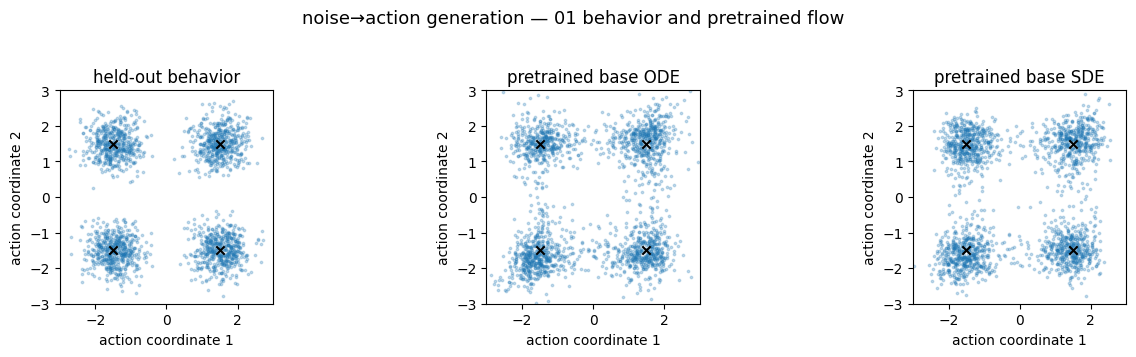

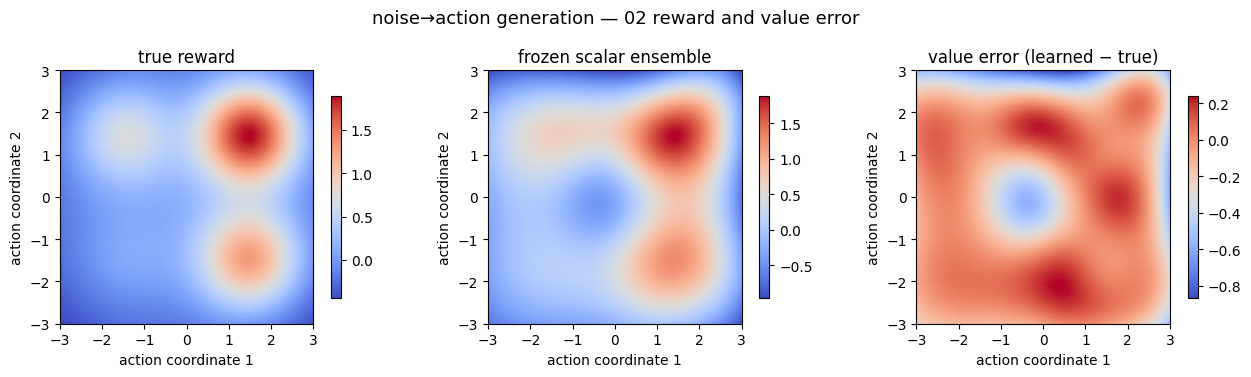

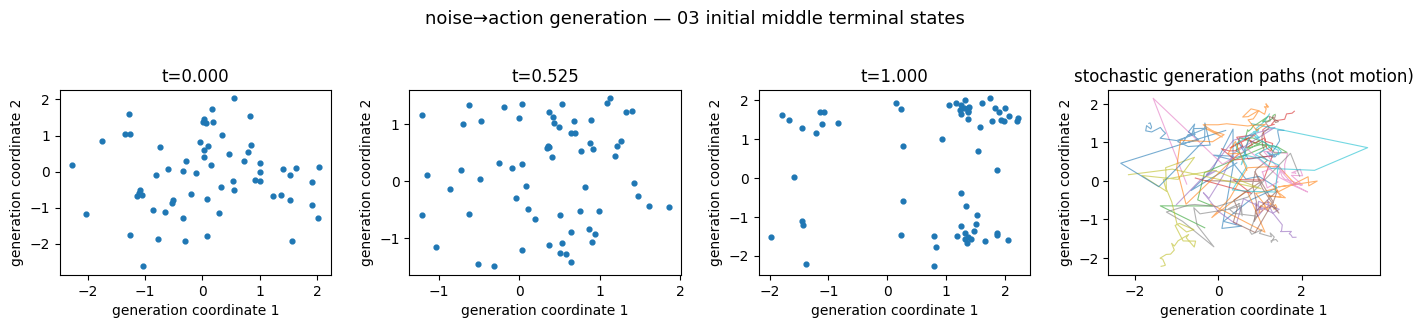

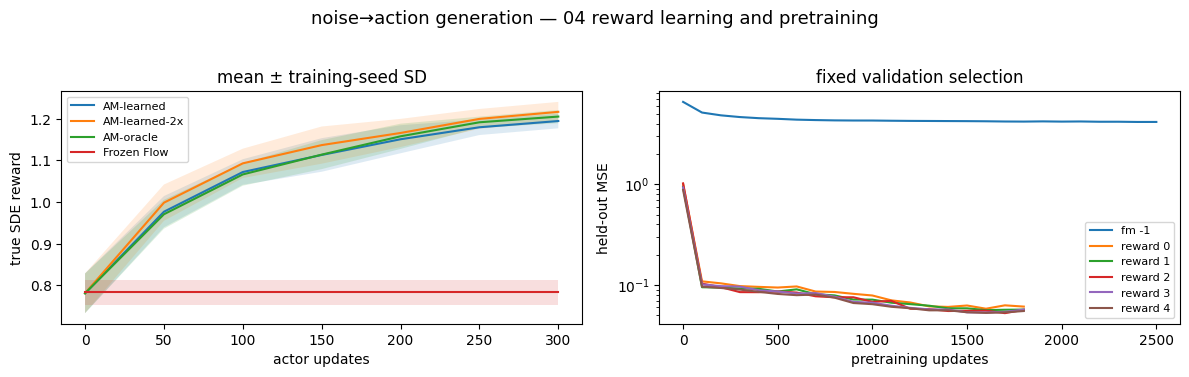

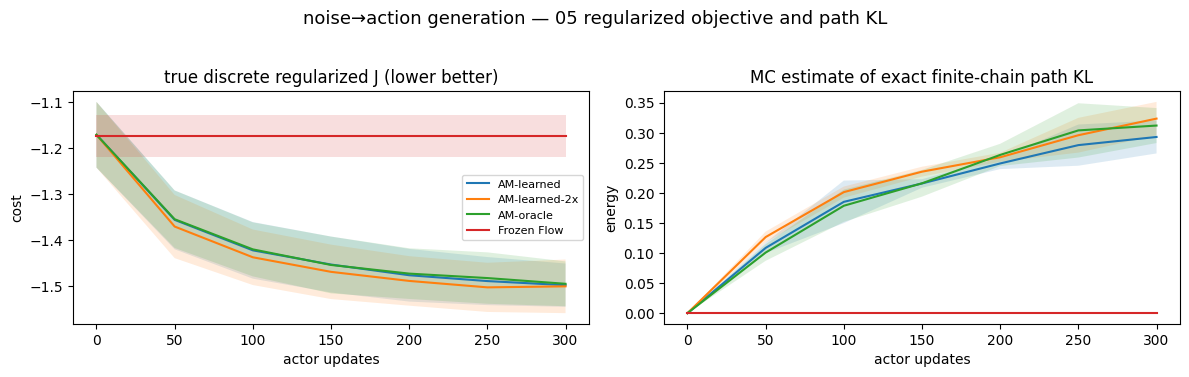

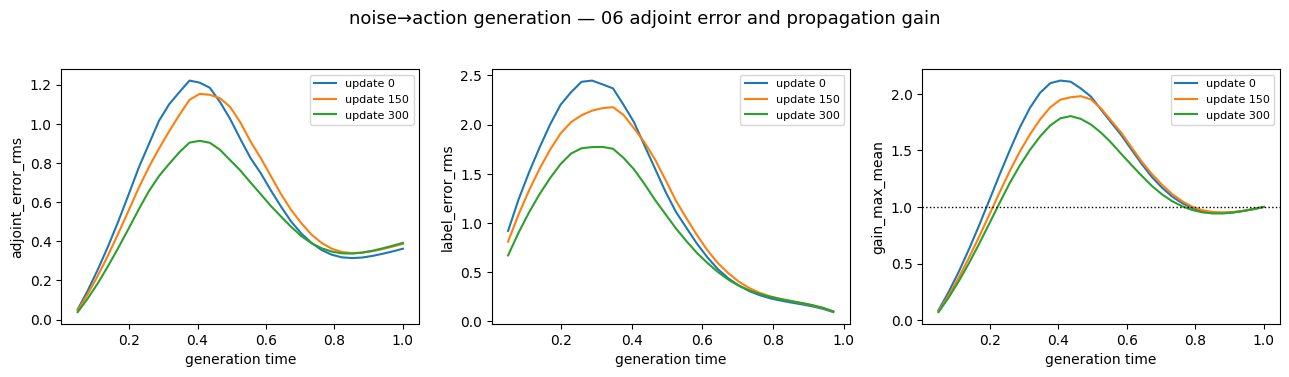

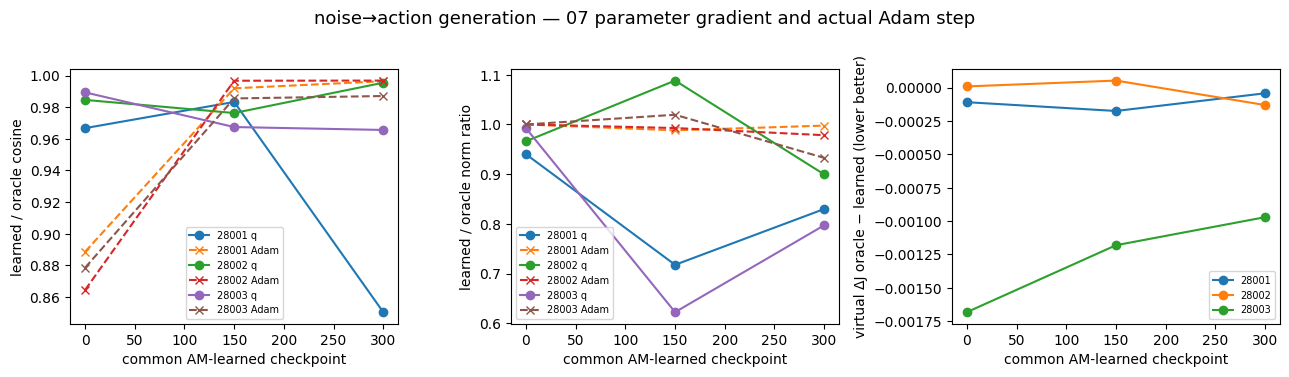

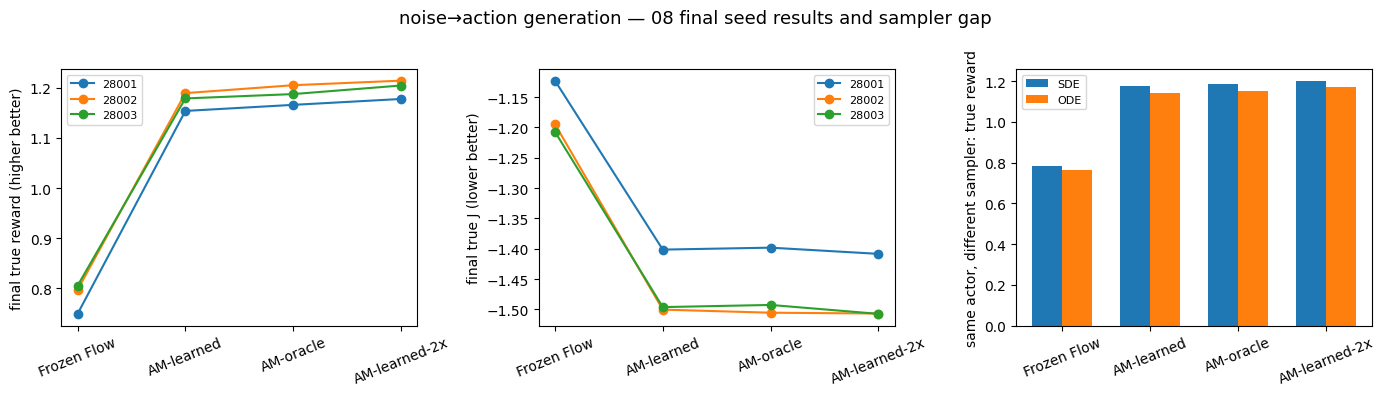

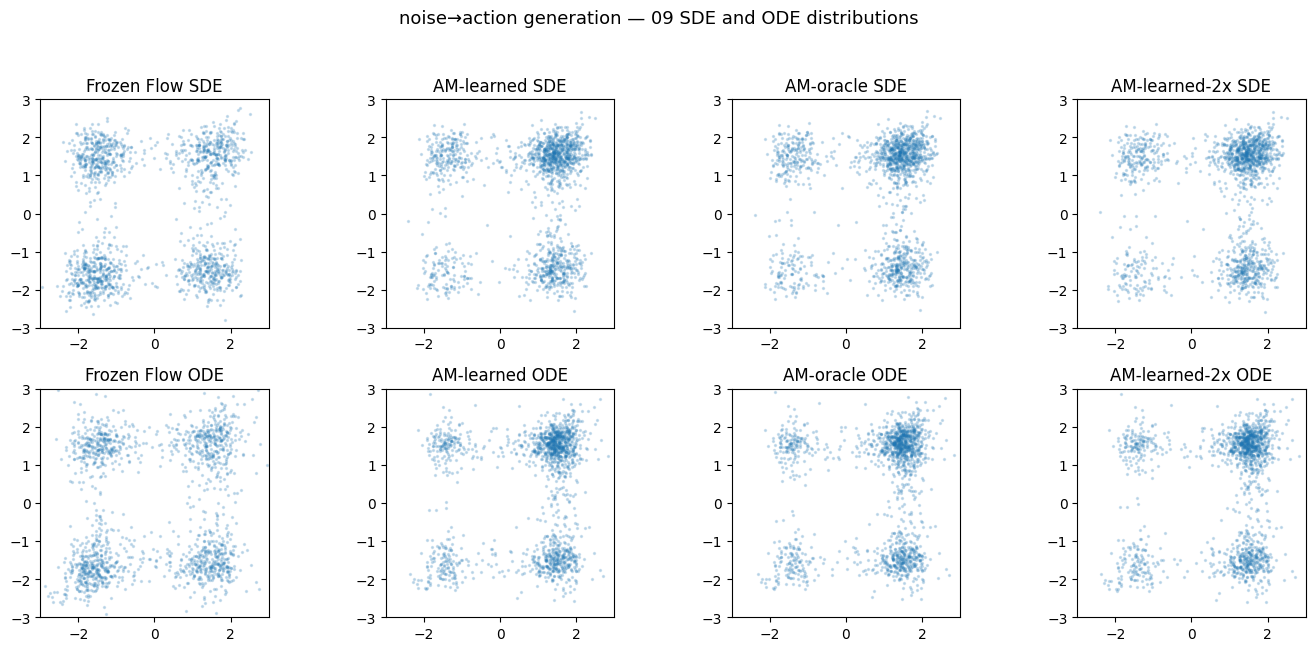

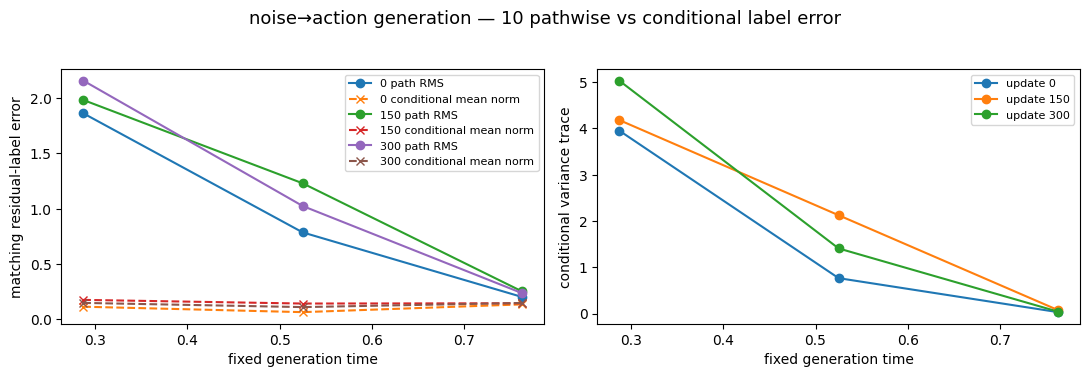

,seed,method,reward,reward_mc_se,cost,cost_mc_se,energy,energy_mc_se
0,28001,Frozen Flow,0.748596,0.009123,-1.122895,0.013685,0.000000,0.000000
3,28001,AM-learned,1.154013,0.008503,-1.401517,0.014345,0.329502,0.002788
6,28001,AM-oracle,1.166139,0.008414,-1.398314,0.014377,0.350895,0.002967
9,28001,AM-learned-2x,1.177900,0.008377,-1.408522,0.014201,0.358328,0.003130
14,28002,Frozen Flow,0.796467,0.008938,-1.194700,0.013407,0.000000,0.000000
17,28002,AM-learned,1.189597,0.008368,-1.500491,0.013856,0.283905,0.002443
20,28002,AM-oracle,1.205398,0.008396,-1.505585,0.013837,0.302513,0.002469
23,28002,AM-learned-2x,1.214493,0.008322,-1.506956,0.013763,0.314783,0.002534
26,28003,Frozen Flow,0.804802,0.009346,-1.207203,0.014019,0.000000,0.000000
29,28003,AM-learned,1.178988,0.008566,-1.496327,0.014041,0.272156,0.002366


reward                cost              energy          
                   mean       std      mean       std      mean       std
method                                                                   
AM-learned     1.174199  0.018269 -1.466112  0.055979  0.295187  0.030292
AM-learned-2x  1.199065  0.018959 -1.474315  0.056979  0.324283  0.030429
AM-oracle      1.186407  0.019661 -1.465560  0.058587  0.314051  0.032642
Frozen Flow    0.783288  0.030332 -1.174933  0.045498  0.000000  0.000000

,seed,method,experiment,sampler,train_K,eval_K,reward,cost,mode_0,mode_1,mode_2,mode_3
0,28001,Frozen Flow,main,SDE,0,32,0.748596,-1.122895,0.272461,0.240967,0.230469,0.256104
1,28001,Frozen Flow,main,SDE,0,64,0.755540,-1.133310,0.273438,0.242432,0.229980,0.254150
2,28001,Frozen Flow,main,ODE,0,128,0.719191,NaN,0.275635,0.233154,0.239014,0.252197
3,28001,AM-learned,main,SDE,32,32,1.154013,-1.401517,0.083984,0.146240,0.250000,0.519775
4,28001,AM-learned,main,SDE,32,64,1.165193,-1.419058,0.082764,0.144775,0.248535,0.523926
5,28001,AM-learned,main,ODE,32,128,1.143278,NaN,0.098877,0.132812,0.266846,0.501465
6,28001,AM-oracle,main,SDE,32,32,1.166139,-1.398314,0.083008,0.138184,0.249023,0.529785
7,28001,AM-oracle,main,SDE,32,64,1.175985,-1.413551,0.081055,0.139893,0.247314,0.531738
8,28001,AM-oracle,main,ODE,32,128,1.154163,NaN,0.092773,0.128418,0.271240,0.507568
9,28001,AM-learned-2x,main,SDE,32,32,1.177900,-1.408522,0.077637,0.132568,0.255127,0.534668


,seed,checkpoint,value_rmse,value_std,value_rmse_over_true_std,gradient_rmse,gradient_relative,gradient_cosine,gradient_cosine_mean,ensemble_gradient_variance,...,step_learned_norm,step_oracle_norm,virtual_learned_reward_delta,virtual_learned_reward_delta_mc_se,virtual_learned_cost_delta,virtual_learned_cost_delta_mc_se,virtual_oracle_reward_delta,virtual_oracle_reward_delta_mc_se,virtual_oracle_cost_delta,virtual_oracle_cost_delta_mc_se
0,28001,0,0.071661,0.600596,0.119316,0.231365,0.322320,0.951009,0.806218,0.025685,...,0.020508,0.020509,0.013232,0.000876,-0.013293,0.001315,0.013641,0.000871,-0.013403,0.001309
1,28001,150,0.073416,0.593900,0.123616,0.211349,0.263844,0.965407,0.843920,0.026442,...,0.004489,0.004543,0.000952,0.000134,-0.000686,0.000187,0.001082,0.000157,-0.000862,0.000222
2,28001,300,0.066949,0.509943,0.131288,0.206532,0.237580,0.971822,0.917134,0.030114,...,0.005287,0.005299,0.000887,0.000120,0.000212,0.000159,0.000981,0.000123,0.000168,0.000166
3,28002,0,0.077871,0.589374,0.132125,0.262402,0.389345,0.941903,0.858512,0.022803,...,0.020509,0.020509,0.011104,0.001034,-0.011118,0.001552,0.011246,0.001049,-0.011110,0.001573
4,28002,150,0.084000,0.542545,0.154825,0.295561,0.359756,0.953551,0.881170,0.026348,...,0.006608,0.006656,0.000425,0.000166,-0.001418,0.000217,0.000606,0.000163,-0.001366,0.000213
5,28002,300,0.085946,0.521723,0.164736,0.310253,0.359701,0.952051,0.922084,0.028481,...,0.006196,0.006333,0.000857,0.000280,0.001043,0.000421,0.001130,0.000290,0.000911,0.000436
6,28003,0,0.063881,0.603078,0.105925,0.229883,0.328046,0.950300,0.861664,0.017092,...,0.020510,0.020510,0.011065,0.001179,-0.010081,0.001777,0.011572,0.001119,-0.011763,0.001682
7,28003,150,0.079779,0.562826,0.141748,0.266111,0.331114,0.954277,0.878978,0.021371,...,0.006662,0.006534,0.001347,0.000291,0.002034,0.000619,0.001550,0.000263,0.000853,0.000572
8,28003,300,0.071123,0.537665,0.132280,0.266559,0.315622,0.960202,0.910741,0.020558,...,0.004929,0.005284,0.001329,0.000135,-0.003572,0.000162,0.001590,0.000153,-0.004543,0.000185


,seed,checkpoint,time,state_index,state_x,state_y,futures,conditional_mean_x,conditional_mean_y,conditional_mean_norm,variance_trace,mean_mc_se_x,mean_mc_se_y,pathwise_rms
0,28001,0,0.2875,0,0.257930,0.051900,256,-0.009150,0.172833,0.173075,2.766541,0.078267,0.068419,1.669038
1,28001,0,0.2875,1,0.595479,1.739311,256,0.037198,0.033296,0.049923,1.617088,0.073889,0.029278,1.270143
2,28001,0,0.2875,2,-1.810308,-1.637286,256,0.024631,0.063829,0.068416,0.487017,0.017039,0.040151,0.699854
3,28001,0,0.5250,0,1.300483,-0.837639,256,0.015423,0.028614,0.032505,0.216917,0.011639,0.026681,0.465969
4,28001,0,0.5250,1,0.699041,0.610164,256,0.052924,0.016903,0.055558,0.900454,0.039699,0.044062,0.948695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,28003,300,0.5250,1,0.899671,0.642404,256,-0.038420,-0.061315,0.072358,0.472911,0.032870,0.027693,0.690144
77,28003,300,0.5250,2,-0.204128,1.442442,256,0.131778,-0.056821,0.143506,5.293440,0.143510,0.009078,2.300730
78,28003,300,0.7625,0,0.835743,1.206370,256,0.014097,-0.117482,0.118325,0.021445,0.008795,0.002535,0.188048
79,28003,300,0.7625,1,1.135600,1.664788,256,-0.130050,-0.168809,0.213095,0.016918,0.007909,0.001880,0.249522


,metric,sampler,seeds,paired_deltas,mean_oracle_minus_learned,seed_sd,seed_se,ci95_low,ci95_high,favorable_seeds
0,reward,SDE,3,"{28001: 0.012126673733291682, 28002: 0.0158014...",0.012208,0.003554,0.002052,0.003380,0.021036,3
1,cost,SDE,3,"{28001: 0.003203381216735579, 28002: -0.005094...",0.000552,0.004893,0.002825,-0.011603,0.012707,1
2,reward,ODE,3,"{28001: 0.010884660136071034, 28002: 0.0139169...",0.010561,0.003529,0.002037,0.001795,0.019327,3


In [5]:
def make_figures(result, c, out):
    saved = []
    def finish(fig, name):
        fig.suptitle('noise→action generation — '+name.replace('_', ' '), fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, .95))
        fig.savefig(out/(name+'.png'), dpi=150, bbox_inches='tight')
        saved.append(name+'.png')
        display(fig)
        plt.close(fig)
    visual = result['visual']
    means = np.asarray(c.means)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for axis, data, title in zip(ax, (visual['data']['heldout'], visual['base_ode'], visual['terminals']['Frozen Flow SDE']),
                                 ('held-out behavior', 'pretrained base ODE', 'pretrained base SDE')):
        axis.scatter(*data[:2000].T, s=3, alpha=.25)
        axis.scatter(*means.T, marker='x', c='black')
        axis.set(title=title, xlabel='action coordinate 1', ylabel='action coordinate 2', xlim=(-3, 3), ylim=(-3, 3), aspect='equal')
    finish(fig, '01_behavior_and_pretrained_flow')
    line = torch.linspace(-3, 3, 100)
    yy, xx = torch.meshgrid(line, line, indexing='ij')
    mesh = torch.stack((xx.flatten(), yy.flatten()), 1)
    with torch.no_grad():
        truth, learned = true_reward(mesh, c), reward_mean(visual['models'], mesh)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for axis, values, title in zip(ax, (truth, learned, learned-truth), ('true reward', 'frozen scalar ensemble', 'value error (learned − true)')):
        im = axis.imshow(values.reshape(100, 100), extent=(-3, 3, -3, 3), origin='lower', cmap='coolwarm')
        axis.set(title=title, xlabel='action coordinate 1', ylabel='action coordinate 2')
        fig.colorbar(im, ax=axis, shrink=.8)
    finish(fig, '02_reward_and_value_error')
    paths = visual['paths']['AM-learned']
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.3))
    for axis, data, when in zip(ax[:3], (visual['initial_noise'], paths[:, c.steps//2], paths[:, -1]),
                                (0., (1+c.epsilon)/2, 1.)):
        axis.scatter(*data.T, s=12)
        axis.set(title=f't={when:.3f}', xlabel='generation coordinate 1', ylabel='generation coordinate 2')
    for path in paths[:12]:
        ax[3].plot(*path.T, alpha=.6, lw=.8)
    ax[3].set(title='stochastic generation paths (not motion)', xlabel='generation coordinate 1', ylabel='generation coordinate 2')
    finish(fig, '03_initial_middle_terminal_states')
    curve = result['curves'][result['curves'].train_K.isin((0, c.steps))]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for method, rows in curve.groupby('method'):
        groups = rows.groupby('update').reward
        mean, sd = groups.mean(), groups.std().fillna(0.)
        ax[0].plot(mean.index, mean, label=method)
        ax[0].fill_between(mean.index, mean-sd, mean+sd, alpha=.15)
    ax[0].set(xlabel='actor updates', ylabel='true SDE reward', title='mean ± training-seed SD')
    for (seed, stage, member), rows in result['fits'].groupby(['seed', 'stage', 'member']):
        if seed == c.seeds[0]:
            ax[1].plot(rows.step, rows.valid_mse, label=f'{stage} {member}')
    ax[1].set(xlabel='pretraining updates', ylabel='held-out MSE', yscale='log', title='fixed validation selection')
    for axis in ax:
        axis.legend(fontsize=8)
    finish(fig, '04_reward_learning_and_pretraining')
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for method, rows in curve.groupby('method'):
        for axis, metric in zip(ax, ('cost', 'energy')):
            group = rows.groupby('update')[metric]
            mean, sd = group.mean(), group.std().fillna(0)
            axis.plot(mean.index, mean, label=method)
            axis.fill_between(mean.index, mean-sd, mean+sd, alpha=.15)
            axis.set(xlabel='actor updates', ylabel=metric)
    ax[0].set_title('true discrete regularized J (lower better)')
    ax[1].set_title('MC estimate of exact finite-chain path KL')
    ax[0].legend(fontsize=8)
    finish(fig, '05_regularized_objective_and_path_KL')
    pr = result['propagation']
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    for checkpoint, rows in pr.groupby('checkpoint'):
        average = rows.groupby('time').mean(numeric_only=True)
        for axis, metric in zip(ax, ('adjoint_error_rms', 'label_error_rms', 'gain_max_mean')):
            axis.plot(average.index, average[metric], label=f'update {checkpoint}')
            axis.set(xlabel='generation time', ylabel=metric)
    ax[2].axhline(1, color='black', ls=':', lw=1)
    for axis in ax:
        axis.legend(fontsize=8)
    finish(fig, '06_adjoint_error_and_propagation_gain')
    diag = result['diagnostic']
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    for seed, rows in diag.groupby('seed'):
        ax[0].plot(rows.checkpoint, rows.q_cosine, '-o', label=f'{seed} q')
        ax[0].plot(rows.checkpoint, rows.step_cosine, '--x', label=f'{seed} Adam')
        ax[1].plot(rows.checkpoint, rows.q_norm_ratio, '-o', label=f'{seed} q')
        ax[1].plot(rows.checkpoint, rows.step_norm_ratio, '--x', label=f'{seed} Adam')
        ax[2].plot(rows.checkpoint, rows.virtual_oracle_cost_delta-rows.virtual_learned_cost_delta, '-o', label=str(seed))
    ax[0].set(ylabel='learned / oracle cosine')
    ax[1].set(ylabel='learned / oracle norm ratio')
    ax[2].set(ylabel='virtual ΔJ oracle − learned (lower better)')
    for axis in ax:
        axis.set_xlabel('common AM-learned checkpoint')
        axis.legend(fontsize=7)
    finish(fig, '07_parameter_gradient_and_actual_Adam_step')
    final = result['final']
    main = final[final.experiment.eq('main') & final.sampler.eq('SDE') & final.eval_K.eq(c.steps)]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for seed, rows in main.groupby('seed'):
        ax[0].plot(rows.method, rows.reward, '-o', label=str(seed))
        ax[1].plot(rows.method, rows.cost, '-o', label=str(seed))
    ax[0].set_ylabel('final true reward (higher better)')
    ax[1].set_ylabel('final true J (lower better)')
    ode = final[final.experiment.eq('main') & final.sampler.eq('ODE')]
    methods = main.method.unique()
    positions = np.arange(len(methods))
    ax[2].bar(positions-.17, [main[main.method.eq(m)].reward.mean() for m in methods], .34, label='SDE')
    ax[2].bar(positions+.17, [ode[ode.method.eq(m)].reward.mean() for m in methods], .34, label='ODE')
    ax[2].set_xticks(positions, methods)
    ax[2].set_ylabel('same actor, different sampler: true reward')
    for axis in ax:
        axis.tick_params(axis='x', rotation=22)
        axis.legend(fontsize=8)
    finish(fig, '08_final_seed_results_and_sampler_gap')
    fig, ax = plt.subplots(2, 4, figsize=(14, 6.6))
    for column, method in enumerate(methods):
        for row, sampler in enumerate(('SDE', 'ODE')):
            action = visual['terminals'][method+' '+sampler]
            ax[row, column].scatter(*action[:1500].T, s=2, alpha=.2)
            ax[row, column].set(title=method+' '+sampler, xlim=(-3, 3), ylim=(-3, 3), aspect='equal')
    finish(fig, '09_SDE_and_ODE_distributions')
    cond = result['conditional']
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for checkpoint, rows in cond.groupby('checkpoint'):
        a = rows.groupby('time').mean(numeric_only=True)
        ax[0].plot(a.index, a.pathwise_rms, '-o', label=f'{checkpoint} path RMS')
        ax[0].plot(a.index, a.conditional_mean_norm, '--x', label=f'{checkpoint} conditional mean norm')
        ax[1].plot(a.index, a.variance_trace, '-o', label=f'update {checkpoint}')
    ax[0].set(xlabel='fixed generation time', ylabel='matching residual-label error')
    ax[1].set(xlabel='fixed generation time', ylabel='conditional variance trace')
    for axis in ax:
        axis.legend(fontsize=8)
    finish(fig, '10_pathwise_vs_conditional_label_error')
    return saved


FIGURES = make_figures(RESULTS, CFG, OUT)
main = RESULTS['final'].query('experiment == "main" and sampler == "SDE" and eval_K == @CFG.steps')
display(main[['seed', 'method', 'reward', 'reward_mc_se', 'cost', 'cost_mc_se', 'energy', 'energy_mc_se']])
display(main.groupby('method')[['reward', 'cost', 'energy']].agg(['mean', 'std']))
display(RESULTS['final'][['seed', 'method', 'experiment', 'sampler', 'train_K', 'eval_K',
                           'reward', 'cost', 'mode_0', 'mode_1', 'mode_2', 'mode_3']])
display(RESULTS['diagnostic'])
display(RESULTS['conditional'])
display(pd.DataFrame(RESULTS['paired']))

## 5. 由结果自动生成结论，保留不确定性

Oracle 与 learned 的三 seed 差值才是统计单位。Student-t 区间只是 n=3 的初步摘要。
无论结果如何，此实验不能证明传播感知抑制优于一般梯度处理、不能建立普适性、
不能把 lean 梯度叫真实策略梯度，也没有测量 ODE action KL。
条件平均、参数投影、Adam history 都可能改变对逐路径误差的判断。
下方报告使用实际结果，不以候选获胜为验收条件。

In [6]:
def make_report(result, c, elapsed):
    lines = [f'# Flow AM execution report ({c.profile})', '',
             f'Seeds: {list(c.seeds)}. {3*len(c.seeds)} main fine-tunes + '
             f'{2 if c.fine_retrain_first_seed else 0} pre-specified first-seed 2K retrains; '
             f'{len(c.seeds)} frozen bases. Fixed final step {c.actor_updates}. Runtime {elapsed:.1f}s.', '',
             'Primary sampler: shared frozen-base RK2 warmup to epsilon, then all-Gaussian EM chain. '
             'This is a truncated-start, finite-step approximation, not exact time-zero memoryless AM. '
             'The complete implemented-chain KL equals expected conditional Gaussian KL; numerical estimates have MC error. '
             'The separate ODE integrates fine velocity from 0 to 1 and has no reported KL.', '',
             'Oracle minus learned paired differences (positive reward is good; negative cost is good):']
    for row in result['paired']:
        lines.extend(['', f'- {row["sampler"]} {row["metric"]}: mean {row["mean_oracle_minus_learned"]:.6f}, '
                      f'seed SD {row["seed_sd"]:.6f}; 95% t interval '
                      f'[{row["ci95_low"]}, {row["ci95_high"]}], favorable seeds {row["favorable_seeds"]}/{row["seeds"]}.'])
    primary = result['paired'][1]
    if primary['ci95_high'] is not None and primary['ci95_high'] < 0:
        interpretation = '该设置观察到可恢复的终端梯度估计损失（按真实离散 J）；尚未证明传播感知处理优于普通梯度处理。'
    elif primary['ci95_low'] is not None and primary['ci95_low'] > 0:
        interpretation = 'Oracle 的真实离散 J 更差；有限预算、优化尺度、离散化和梯度噪声可能交互，不能自动判 learned 实现有错。'
    else:
        interpretation = '三 seed 的真实离散 J 差异区间包含零，尚未确认稳定收益空间；这既不是普适证明，也不否定理论动机。'
    lines.extend(['', interpretation, '',
                  'Reward, regularized J and ODE/SDE outcomes must be interpreted separately. '
                  'Ensemble disagreement is not a calibrated error estimate; all mechanism diagnostics use common learned-actor checkpoints. '
                  'Virtual Adam steps clone the current optimizer state and use fresh common evaluation noise without changing formal training.', '',
                  'No new candidate, covariance regularizer, damping, guard, adaptive beta or oracle-dependent checkpoint selection was introduced. '
                  'Learned branches made zero new true reward/gradient queries during updates. '
                  'The first-seed K/2K retrain is not a three-seed convergence study. '
                  'Diagnostics query truth only outside the learned-training guard.', '',
                  f'Implementation checks: {sum(x["passed"] for x in result["audits"])}/{len(result["audits"])}. '
                  'Failed executions, if any, remain in their separate events.jsonl; no trajectory clipping or nan_to_num.'])
    return '\n'.join(lines)+'\n'


REPORT = make_report(RESULTS, CFG, time.monotonic()-START)
(OUT/'report.md').write_text(REPORT)
save_json(OUT/'completion.json', dict(status='complete', config_sha256=CONFIG_SHA, profile=CFG.profile,
          seeds=list(CFG.seeds), figures=FIGURES, checks=len(RESULTS['audits']),
          elapsed_seconds=time.monotonic()-START, source_sha256=hashlib.sha256(
              (ROOT/'notebooks/02_flow_am_terminal_gradient.py').read_bytes()).hexdigest()))
display(Markdown(REPORT))
print('All outputs:', OUT.relative_to(ROOT))

# Flow AM execution report (formal)

Seeds: [28001, 28002, 28003]. 9 main fine-tunes + 2 pre-specified first-seed 2K retrains; 3 frozen bases. Fixed final step 300. Runtime 49.5s.

Primary sampler: shared frozen-base RK2 warmup to epsilon, then all-Gaussian EM chain. This is a truncated-start, finite-step approximation, not exact time-zero memoryless AM. The complete implemented-chain KL equals expected conditional Gaussian KL; numerical estimates have MC error. The separate ODE integrates fine velocity from 0 to 1 and has no reported KL.

Oracle minus learned paired differences (positive reward is good; negative cost is good):

- SDE reward: mean 0.012208, seed SD 0.003554; 95% t interval [0.003379884381169918, 0.021035814475634212], favorable seeds 3/3.

- SDE cost: mean 0.000552, seed SD 0.004893; 95% t interval [-0.011602779025240432, 0.012706827519742246], favorable seeds 1/3.

- ODE reward: mean 0.010561, seed SD 0.003529; 95% t interval [0.0017953484410397728, 0.01932688927612064], favorable seeds 3/3.

三 seed 的真实离散 J 差异区间包含零，尚未确认稳定收益空间；这既不是普适证明，也不否定理论动机。

Reward, regularized J and ODE/SDE outcomes must be interpreted separately. Ensemble disagreement is not a calibrated error estimate; all mechanism diagnostics use common learned-actor checkpoints. Virtual Adam steps clone the current optimizer state and use fresh common evaluation noise without changing formal training.

No new candidate, covariance regularizer, damping, guard, adaptive beta or oracle-dependent checkpoint selection was introduced. Learned branches made zero new true reward/gradient queries during updates. The first-seed K/2K retrain is not a three-seed convergence study. Diagnostics query truth only outside the learned-training guard.

Implementation checks: 57/57. Failed executions, if any, remain in their separate events.jsonl; no trajectory clipping or nan_to_num.


All outputs: runs/02-flow-am-formal-drdkjy4g
